# Week 13 SQL–Python Pipeline

Place your `community_followup.sqlite` file in the same folder as this notebook. Complete each TODO and document the intended grain of every query.


In [2]:
"""from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("community_followup.sqlite")
assert DB_PATH.exists(), f"Database not found: {DB_PATH.resolve()}"
"""
from pathlib import Path
import sqlite3
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

DB_PATH = Path("community_followup.sqlite")
assert DB_PATH.is_file(), f"Upload the database to the notebook's working directory: {DB_PATH.resolve()}"

## 1 Connect and inspect tables


In [4]:
"""connection = sqlite3.connect(DB_PATH)
connection.execute("PRAGMA foreign_keys = ON")
# TODO: query sqlite_schema and confirm the five expected tables exist
"""

connection = sqlite3.connect(DB_PATH.resolve().as_uri() + "?mode=ro", uri=True)
connection.execute("PRAGMA foreign_keys = ON")

# Grain: one row per user-created SQLite table.
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_schema WHERE type = 'table' AND name NOT LIKE 'sqlite_%' ORDER BY name",
    connection,
)
expected_tables = {"clinics", "patients", "encounters", "referrals", "followups"}
assert expected_tables <= set(tables["name"]), "An expected table is missing."
display(tables)

,name
0,clinics
1,encounters
2,followups
3,patients
4,referrals


## 2 Referral-level extract

**Intended grain:** one row per referral.


In [6]:
"""referral_query =
-- TODO: join referrals, encounters, clinics, patients, and followups
-- Include referral_id, clinic_name, service_type, due_date, completion_date,
-- social_needs_flag, outcome, and contact_attempts.
referrals = pd.read_sql_query(referral_query, connection)
display(referrals.head())
"""

referral_query = '''
SELECT r.referral_id, c.clinic_name, r.service_type, r.due_date,
       f.completion_date, p.social_needs_flag, f.outcome, f.contact_attempts
FROM referrals AS r
LEFT JOIN encounters AS e ON e.encounter_id = r.encounter_id
LEFT JOIN clinics AS c ON c.clinic_id = e.clinic_id
LEFT JOIN patients AS p ON p.patient_id = e.patient_id
LEFT JOIN followups AS f ON f.referral_id = r.referral_id
ORDER BY r.referral_id
'''
referrals = pd.read_sql_query(referral_query, connection)
display(referrals.head())

,referral_id,clinic_name,service_type,due_date,completion_date,social_needs_flag,outcome,contact_attempts
0,R001,Northside Clinic,Medication review,2026-08-17,2026-08-13,1,Completed on time,1
1,R002,Riverbend Clinic,Social work,2026-08-19,2026-08-18,0,Completed on time,2
2,R003,Mountain View Clinic,Nutrition,2026-08-14,2026-08-14,0,Completed on time,3
3,R004,Northside Clinic,Care coordination,2026-08-23,2026-08-21,0,Completed on time,1
4,R005,Riverbend Clinic,Medication review,2026-08-25,2026-08-26,1,Completed late,2


## 3 Validate the extract


In [7]:
"""# TODO: add at least three assertions. Include expected row count, unique referral_id,
# and a check that the joined clinic field is not missing.
"""

# Grain: one result row containing the source table's total referral count.
expected_count = connection.execute("SELECT COUNT(*) FROM referrals").fetchone()[0]
assert len(referrals) == expected_count, "The join changed the referral count."
assert referrals["referral_id"].notna().all() and referrals["referral_id"].is_unique
assert referrals["clinic_name"].notna().all(), "At least one referral has no clinic."
assert referrals["social_needs_flag"].isin([0, 1]).all(), "A patient link or flag is missing."
print(f"Validated {expected_count} referrals.")

Validated 40 referrals.


## 4 Transform and summarize


In [8]:
"""def add_completion_fields(frame):
    # TODO: copy the frame, parse due and completion dates, and create completed/on_time fields
    pass

analysis = add_completion_fields(referrals)
# TODO: create a clinic summary with referral counts and on-time rate
"""

def add_completion_fields(frame):
    result = frame.copy()
    for column in ("due_date", "completion_date"):
        result[column] = pd.to_datetime(result[column], format="%Y-%m-%d", errors="raise")
    assert result["due_date"].notna().all(), "A referral is missing its due date."
    result["completed"] = result["completion_date"].notna()
    result["on_time"] = result["completed"] & result["completion_date"].le(result["due_date"])
    return result

analysis = add_completion_fields(referrals)
clinic_summary = (
    analysis.groupby("clinic_name", as_index=False)
    .agg(
        referral_count=("referral_id", "size"),
        completed_count=("completed", "sum"),
        on_time_count=("on_time", "sum"),
        on_time_rate=("on_time", "mean"),
    )
)
display(clinic_summary.assign(on_time_rate=clinic_summary["on_time_rate"].map("{:.1%}".format)))

,clinic_name,referral_count,completed_count,on_time_count,on_time_rate
0,Mountain View Clinic,13,10,3,23.1%
1,Northside Clinic,14,12,12,85.7%
2,Riverbend Clinic,13,11,5,38.5%


## 5 Visualization and interpretation


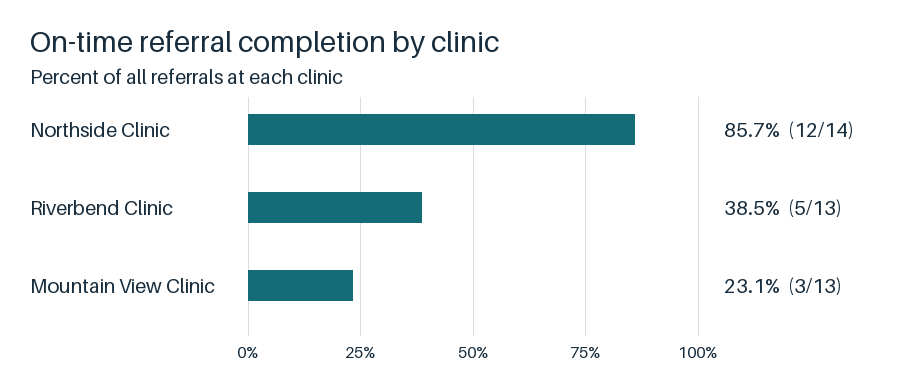

In [9]:
"""# TODO: create and save one chart that supports the portfolio question
"""

chart_data = clinic_summary.sort_values("on_time_rate", ascending=False)
chart = Image.new("RGB", (920, 155 + 78 * len(chart_data)), "white")
draw = ImageDraw.Draw(chart)
title_font = ImageFont.load_default(size=29)
label_font = ImageFont.load_default(size=20)
small_font = ImageFont.load_default(size=16)
ink = "#172C3C"
draw.text((30, 23), "On-time referral completion by clinic", font=title_font, fill=ink)
draw.text((30, 64), "Percent of all referrals at each clinic", font=label_font, fill=ink)

bar_left, bar_width = 248, 450
axis_y = 101 + 78 * len(chart_data)
for percent in (0, 25, 50, 75, 100):
    x = bar_left + bar_width * percent // 100
    draw.line((x, 97, x, axis_y), fill="#D5DEE4")
    draw.text((x, axis_y + 12), f"{percent}%", font=small_font, anchor="mt", fill=ink)

for index, row in enumerate(chart_data.itertuples(index=False)):
    y = 114 + 78 * index
    draw.text((30, y + 15), row.clinic_name, font=label_font, anchor="lm", fill=ink)
    if row.on_time_rate > 0:
        draw.rectangle((bar_left, y, bar_left + round(bar_width * row.on_time_rate), y + 30),
                       fill="#146C78")
    label = f"{row.on_time_rate:.1%}  ({row.on_time_count}/{row.referral_count})"
    draw.text((724, y + 15), label, font=label_font, anchor="lm", fill=ink)

chart.save("on_time_referral_completion_by_clinic.png")
display(chart)

**Interpretation and limitation:**

[Write a plain-language interpretation and one limitation.]


Interpretation and limitation

Northside Clinic had the highest observed on-time completion rate at 85.7% (12 of 14 referrals), followed by Riverbend Clinic at 38.5% (5 of 13) and Mountain View Clinic at 23.1% (3 of 13). Overall, 20 of 40 referrals (50.0%) were completed on time. Each clinic had only 13 or 14 referrals, so a few cases can substantially change its rate.

## 6 Second SQL query

Write a grouped SQL query by clinic or service. Compare it with the Pandas summary and explain any difference.


In [12]:
"""summary_query =
-- TODO
sql_summary = pd.read_sql_query(summary_query, connection)
display(sql_summary)
"""

# Grain: one row per clinic.
summary_query = '''
SELECT c.clinic_name,
       COUNT(*) AS referral_count,
       COUNT(f.completion_date) AS completed_count,
       SUM(CASE WHEN DATE(f.completion_date) <= DATE(r.due_date)
                THEN 1 ELSE 0 END) AS on_time_count,
       AVG(CASE WHEN DATE(f.completion_date) <= DATE(r.due_date)
                THEN 1.0 ELSE 0.0 END) AS on_time_rate
FROM referrals AS r
LEFT JOIN encounters AS e ON e.encounter_id = r.encounter_id
LEFT JOIN clinics AS c ON c.clinic_id = e.clinic_id
LEFT JOIN followups AS f ON f.referral_id = r.referral_id
GROUP BY c.clinic_name
ORDER BY c.clinic_name
'''
sql_summary = pd.read_sql_query(summary_query, connection)
pd.testing.assert_frame_equal(
    sql_summary, clinic_summary, check_exact=False, rtol=1e-12, atol=1e-12
)
display(sql_summary.assign(on_time_rate=sql_summary["on_time_rate"].map("{:.1%}".format)))
print("SQL and Pandas match for all clinics.")

,clinic_name,referral_count,completed_count,on_time_count,on_time_rate
0,Mountain View Clinic,13,10,3,23.1%
1,Northside Clinic,14,12,12,85.7%
2,Riverbend Clinic,13,11,5,38.5%


SQL and Pandas match for all clinics.


## 7 AI use and verification

Document the task, prompt, response, test, correction, and judgment.


In [ ]:
connection.close()
print("Connection closed.")


Comparison. SQL and Pandas produced the same referral counts, completion counts, on-time counts, and rates for each clinic. Both used the same inclusive due-date rule and divided by all referrals.
7 AI use and verification
- Task: Complete and verify the Week 13 SQL–Python referral analysis.
- Prompt: “Help me answer the week 13 Questions and with the associated code needed to complete the questions”
- Response: Codex drafted the joins, assertions, date transformation, clinic summaries, chart, and interpretation.
- Test: Codex ran the notebook code against the supplied SQLite database. It validated the 40-row extract, checked unique referral IDs and clinic assignments, and compared the SQL and Pandas clinic summaries.
- Correction: The starter’s TODOs were replaced with working code. The analysis states the denominator explicitly and preserves referrals with no follow-up through a LEFT JOIN.
- Judgment: The all-referrals denominator fits the question about how often referrals were completed on time. The clinic rates describe this dataset and should be interpreted in light of the small counts.
Update this entry after your own Colab run to reflect the tests you performed and any corrections you made.